# 02 · Baselines and the REE benchmark on the validation year

The reference points every later model is measured against (DESIGN §7.1, §7.6, §8), scored on the
validation year, 2024-11-01 to 2025-10-31. Run `make evaluate` first: this notebook only reads
`data/predictions/validation/` and `reports/results/validation.csv`.

**Protocol.** Each forecast is issued at 10:00 local time for the 24 hours of the next day
(rolling origin, one forecast per day). The blackout days, 28–29 April 2025, are not scored.

**Models**

| Name | Point forecast |
|---|---|
| `naive_weekly` | same local hour one week earlier |
| `naive_daily` | latest observed value of the same hour: yesterday before 10:00, two days back otherwise |
| `climatology` | mean by day type, week of year and hour over all earlier data |
| `climatology_adjusted` | the same, rescaled to the level of the last 28 days |
| `ree` | REE's published day-ahead forecast (ESIOS 1775), the professional benchmark |

**Uncertainty.** All five are point forecasts. Each gets quantiles the same way: the empirical
quantiles, by hour, of its own errors over the previous 365 days, using only errors already known
at issue time. The seven levels are 5, 10, 25, 50, 75, 90 and 95%. REE publishes no uncertainty,
so "REE + its own past errors" is our construction, not REE's product.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from loadforecast.config import DATA_DIR, PROCESSED_DIR, ROOT, load_config
from loadforecast.evaluation import metrics, scoring
from loadforecast.models.quantiles import quantile_column

pd.set_option("display.width", 200, "display.max_columns", 30, "display.float_format", "{:,.2f}".format)
plt.rcParams.update({"figure.dpi": 90, "savefig.dpi": 130, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})
FIG = ROOT / "reports" / "figures"
SPLIT = "validation"
cfg = load_config("backtest")
TAUS = cfg["quantiles"]
QCOLS = [quantile_column(t) for t in TAUS]
MODELS = ["naive_weekly", "naive_daily", "climatology", "climatology_adjusted", "ree"]
COLORS = dict(zip(MODELS, ["C0", "C1", "C2", "C4", "C3"], strict=True))

table = pd.read_parquet(PROCESSED_DIR / "hourly.parquet")
scored = {m: scoring.join_actual(pd.read_parquet(DATA_DIR / "predictions" / SPLIT / f"{m}.parquet"), table)
          for m in MODELS}
results = pd.read_csv(ROOT / "reports" / "results" / f"{SPLIT}.csv", index_col=0)
print(f"{SPLIT}: {cfg['splits'][SPLIT]['start']} to {cfg['splits'][SPLIT]['end']}, "
      f"{len(scored['ree']):,} scored hours on {scored['ree']['local_date'].nunique()} days")

validation: 2024-11-01 to 2025-10-31, 8,712 scored hours on 363 days


## 1. How the forecasts are scored

A reference for every number in this notebook and in `reports/results/`. Notation: $y_t$ is the
realised hourly demand, $\hat y_t$ the point forecast, $q_{t,\tau}$ the forecast quantile at level
$\tau$ (the value demand should stay below with probability $\tau$), and $n$ the number of scored
hours. The code is in `loadforecast/evaluation/metrics.py` and `dm_test.py`.

### Point forecasts

| Metric | Definition | How to read it |
|---|---|---|
| **MAE** | $\frac1n\sum_t \lvert \hat y_t - y_t\rvert$ | Typical size of the error in MW. Every MW of error counts the same. |
| **RMSE** | $\sqrt{\frac1n\sum_t (\hat y_t - y_t)^2}$ | Also in MW, but large errors count more. RMSE well above MAE means a few very bad hours. |
| **MAPE** | $\frac{100}{n}\sum_t \frac{\lvert \hat y_t - y_t\rvert}{y_t}$ | Error as a percentage of demand; the figure grid operators usually quote. Safe here because demand is never near zero. An error of 500 MW weighs more at night (low demand) than at the evening peak. |
| **Bias** | $\frac1n\sum_t (\hat y_t - y_t)$ | Positive means the forecast is too high on average. A forecast can have zero bias and still be poor. |

### Skill score

$$\mathrm{SS} = 1 - \frac{L_\text{model}}{L_\text{reference}}$$

for a loss $L$ (MAE or CRPS). 1 is a perfect forecast, 0 is no better than the reference, negative
is worse. The reference here is `naive_weekly`. A skill of 0.68 means the loss is 68% lower than the reference's.

### Probabilistic forecasts

**Pinball loss** of one quantile forecast:

$$\rho_\tau(y, q) = \begin{cases}\tau\,(y - q) & y \ge q\\ (1-\tau)\,(q - y) & y < q\end{cases}$$

It penalises the two sides unequally. For $\tau = 0.95$, an outcome above the quantile costs 19
times more per MW than one below it, so the loss is smallest when the quantile really is exceeded
5% of the time. For $\tau = 0.5$ it is half the absolute error.

**CRPS** (continuous ranked probability score) scores the whole predictive distribution $F$:

$$\mathrm{CRPS}(F, y) = \int_{-\infty}^{\infty}\big(F(x) - \mathbb 1[x \ge y]\big)^2\,dx
  = \mathbb E\lvert X - y\rvert - \tfrac12\,\mathbb E\lvert X - X'\rvert ,\quad X, X' \sim F .$$

- It is in MW and smaller is better. It rewards distributions that are both centred on the
  outcome and narrow, and it cannot be improved by quoting bands wider or narrower than one believes.
- For a point forecast (no uncertainty) it equals the absolute error, so **CRPS and MAE are directly
  comparable**: a probabilistic forecast should have a CRPS below its own MAE.
- CRPS equals twice the pinball loss integrated over all levels. We approximate it from the seven
  quantiles: $\mathrm{CRPS} \approx \frac{2}{7}\sum_{\tau}\rho_\tau(y, q_\tau)$ with
  $\tau \in \{0.05, 0.1, 0.25, 0.5, 0.75, 0.9, 0.95\}$.
- **Caveat.** The approximation is the same for every model, so comparisons are fair, but it is not
  the exact CRPS: the levels are unevenly spaced and nothing beyond 5% and 95% is scored. Absolute
  values are not comparable with CRPS figures computed from samples or reported elsewhere.

**Calibration** asks whether the stated probabilities are true.

| Check | Definition | How to read it |
|---|---|---|
| **Coverage** (`cov50`, `cov80`, `cov90`) | Share of hours with $q_{t,\tau_\text{lo}} \le y_t \le q_{t,\tau_\text{hi}}$, for the pairs (25%, 75%), (10%, 90%) and (5%, 95%) | Should equal the nominal 50, 80 and 90%. Below: bands too narrow (overconfident). Above: too wide. |
| **Reliability diagram** | For each $\tau$, the share of hours with $y_t \le q_{t,\tau}$, plotted against $\tau$ | Calibrated forecasts lie on the diagonal. A curve entirely below it means the forecast is too high (bias); an S-shape means bands too narrow or too wide. |
| **PIT histogram** | Histogram of $F_t(y_t)$, here counted in the bins between our quantile levels | Flat if calibrated. Peaks at both ends: bands too narrow. A slope: bias. |

**Sharpness** (`width50`, `width80`, `width90`) is the mean width of those intervals in MW.
Narrower is better, **but only among calibrated forecasts**: a narrow band that misses is not an
achievement. The rule is calibration first, then sharpness.

### Is a difference between two models real?

One year of hourly errors is far fewer than 8,760 independent observations, because errors are
correlated within a day and from one day to the next. Both tools below work on **one loss value per
day**, the difference $\delta_d$ between the daily MAE of two models.

- **Diebold–Mariano test.** $\mathrm{DM} = \bar\delta \big/ \sqrt{\widehat{\mathrm{LRV}}(\delta)/n}$,
  compared with a standard normal. $\widehat{\mathrm{LRV}}$ is a Newey–West estimate of the
  long-run variance, which allows for day-to-day correlation. A small p-value (`dm_p`) means the two
  models' expected losses differ.
- **Block bootstrap interval** (`ci_low`, `ci_high`). Resample the year in blocks of 7 consecutive
  days, 2,000 times, and take the central 95% of the resampled mean difference. If the interval
  excludes zero, the difference is unlikely to be luck. It also shows the *size* of the difference,
  which the p-value does not.

### What is scored

All hours of the split except the masked blackout days. Hourly values are averaged with equal
weight, so the 23- and 25-hour clock-change days weigh slightly less and more than the others.

## 2. Headline scores

MAE, RMSE, bias and CRPS are in MW; MAPE in %. Skill is relative to `naive_weekly`
(1 is perfect, 0 is no better). CRPS is approximated from the seven quantiles, the same way for every model.

In [2]:
print(results[["MAE", "RMSE", "MAPE", "bias", "CRPS", "skill_MAE", "skill_CRPS"]].round(3).to_string())

                          MAE     RMSE  MAPE    bias     CRPS  skill_MAE  skill_CRPS
model                                                                               
naive_daily          2,442.86 3,358.29  9.08   -2.44 1,390.05      -0.70       -0.54
naive_weekly         1,438.06 2,092.41  5.29   -0.09   903.01       0.00        0.00
climatology_adjusted 1,233.93 1,637.16  4.53  -14.10   695.73       0.14        0.23
climatology          1,221.00 1,617.71  4.47 -153.30   695.70       0.15        0.23
lgbm_forecast          537.99   731.36  1.99  -23.58   315.12       0.63        0.65
lgbm_oracle            523.02   712.99  1.94   29.49   307.65       0.64        0.66
ree                    454.87   640.76  1.67   10.61   270.54       0.68        0.70


### Is each baseline significantly worse than REE?

Difference in daily MAE (model minus REE), with a 95% block-bootstrap interval (blocks of 7 days)
and the Diebold–Mariano p-value with a Newey–West variance.

In [3]:
print(results.loc[results.index != "ree", ["MAE_minus_ree", "ci_low", "ci_high", "dm_p"]].to_string(
    float_format=lambda v: f"{v:,.3g}"))

                      MAE_minus_ree   ci_low  ci_high      dm_p
model                                                          
naive_daily                1.99e+03 1.88e+03  2.1e+03 1.19e-255
naive_weekly                    983      783 1.19e+03  1.24e-23
climatology_adjusted            779      639      932  1.02e-27
climatology                     766      628      937  1.84e-23
lgbm_forecast                  83.1     37.5      130  0.000321
lgbm_oracle                    68.2       24      113   0.00248


## 3. Where the errors are

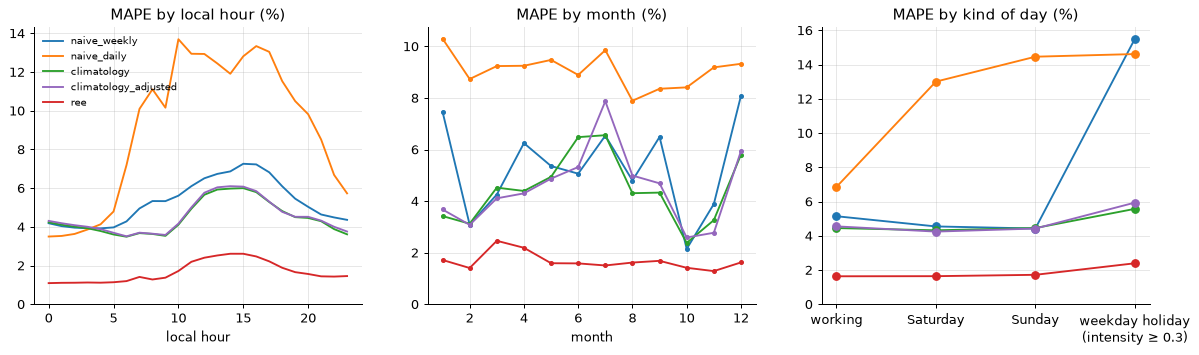

MAPE (%) by condition:
                      cold (<10 °C)  mild  hot (>22 °C)  holidays  Mondays
naive_weekly                   5.43  5.10          5.56     15.50     4.93
naive_daily                    7.99  9.14          9.58     14.61    12.14
climatology                    4.07  3.82          5.84      5.57     5.24
climatology_adjusted           4.13  3.85          5.96      5.94     5.44
ree                            1.41  1.75          1.68      2.39     1.83


In [4]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for m in MODELS:
    s = scored[m]
    ape = 100 * (s["point"] - s["y"]).abs() / s["y"]
    axes[0].plot(ape.groupby(s["local_hour"]).mean(), color=COLORS[m], label=m)
    axes[1].plot(ape.groupby(s["local_date"].dt.month).mean(), color=COLORS[m], marker=".")
    info = s.join(table[["day_type", "holiday_intensity"]])
    kind = np.where(info["holiday_intensity"] >= 0.3, "holiday", info["day_type"])
    by = ape.groupby(kind).mean().reindex(["working", "saturday", "sunday_holiday", "holiday"])
    axes[2].plot(range(4), by.values, color=COLORS[m], marker="o")
axes[0].set(title="MAPE by local hour (%)", xlabel="local hour")
axes[1].set(title="MAPE by month (%)", xlabel="month")
axes[2].set(title="MAPE by kind of day (%)", xticks=range(4),
            xticklabels=["working", "Saturday", "Sunday", "weekday holiday\n(intensity ≥ 0.3)"])
axes[0].legend(frameon=False, fontsize=8)
for ax in axes:
    ax.set_ylim(0)
fig.savefig(FIG / "baselines_errors.png", bbox_inches="tight")
plt.show()

rows = {}
for m in MODELS:
    s = scored[m].join(table[["day_type", "holiday_intensity", "temp_obs"]])
    ape = 100 * (s["point"] - s["y"]).abs() / s["y"]
    regime = pd.cut(s["temp_obs"], [-20, 10, 22, 50], labels=["cold (<10 °C)", "mild", "hot (>22 °C)"])
    rows[m] = pd.concat([ape.groupby(regime, observed=True).mean(),
                         pd.Series({"holidays": ape[s["holiday_intensity"] >= 0.3].mean(),
                                    "Mondays": ape[s["local_date"].dt.day_of_week == 0].mean()})])
print("MAPE (%) by condition:")
print(pd.DataFrame(rows).T.round(2).to_string())

## 4. Are the uncertainty bands honest?

Left: for each quantile level, how often the outcome fell below the forecast quantile. A calibrated
forecast lies on the diagonal. Right: the histogram of $F(y)$ (PIT), flat if calibrated; outcomes
outside the 5–95% range pile up in the end bins.

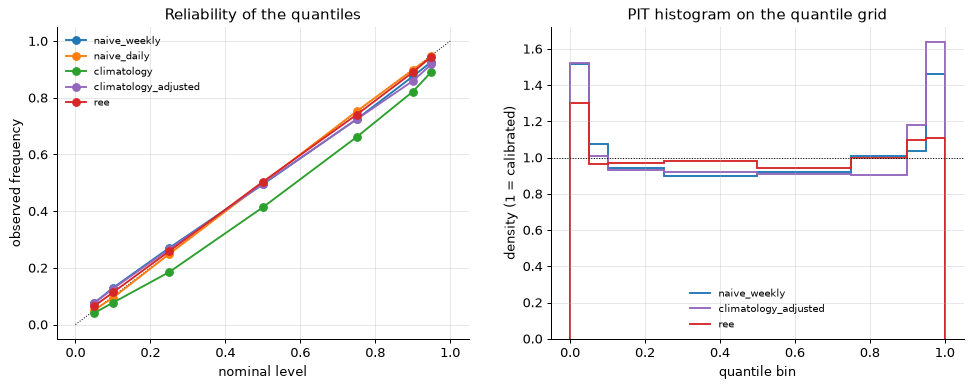

Observed frequency below each quantile (%):
                      0.05   0.1  0.25   0.5  0.75   0.9  0.95
naive_weekly          7.60 12.90 27.00 49.40 72.40 87.50 92.70
naive_daily           5.10  9.50 24.90 49.90 75.20 89.80 94.60
climatology           4.10  7.70 18.50 41.40 66.10 82.10 89.20
climatology_adjusted  7.60 12.60 26.60 49.60 72.40 85.90 91.80
ree                   6.50 11.30 25.90 50.40 74.00 89.00 94.50

Coverage of central intervals (%) and mean width (MW):
                      cov50  cov80  cov90  width50  width80  width90
model                                                               
naive_daily           50.30  80.30  89.50 4,515.10 8,674.60 9,940.20
naive_weekly          45.40  74.60  85.10 1,832.20 3,909.40 5,449.00
climatology_adjusted  45.80  73.30  84.20 1,599.30 3,191.70 4,276.00
climatology           47.60  74.40  85.00 1,677.00 3,294.60 4,363.40
lgbm_forecast         48.20  78.60  88.40   826.80 1,613.20 2,112.60
lgbm_oracle           48.30  78.60  89.

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot([0, 1], [0, 1], color="k", lw=0.8, ls=":")
cal = {}
for m in MODELS:
    s = scored[m].dropna(subset=QCOLS)
    freq = [(s["y"] <= s[c]).mean() for c in QCOLS]
    cal[m] = freq
    axes[0].plot(TAUS, freq, marker="o", color=COLORS[m], label=m)
axes[0].set(xlabel="nominal level", ylabel="observed frequency", title="Reliability of the quantiles")
axes[0].legend(frameon=False, fontsize=8)
bins = np.array([0, 0.05, 0.1, 0.25, 0.5, 0.75, 0.9, 0.95, 1.0])
for m in ("naive_weekly", "climatology_adjusted", "ree"):
    s = scored[m].dropna(subset=QCOLS)
    below = np.column_stack([(s["y"] <= s[c]).to_numpy() for c in QCOLS])
    position = below.shape[1] - below.sum(axis=1)       # index of the bin the outcome fell in
    density = np.bincount(position, minlength=8) / len(s) / np.diff(bins)
    axes[1].stairs(density, bins, color=COLORS[m], label=m, lw=1.5)
axes[1].axhline(1, color="k", lw=0.8, ls=":")
axes[1].set(xlabel="quantile bin", ylabel="density (1 = calibrated)", title="PIT histogram on the quantile grid")
axes[1].legend(frameon=False, fontsize=8)
fig.savefig(FIG / "baselines_calibration.png", bbox_inches="tight")
plt.show()
print("Observed frequency below each quantile (%):")
print((100 * pd.DataFrame(cal, index=[f"{t:g}" for t in TAUS]).T).round(1).to_string())
print("\nCoverage of central intervals (%) and mean width (MW):")
print(results[["cov50", "cov80", "cov90", "width50", "width80", "width90"]].round(1).to_string())

In [6]:
rows = {}
for m in MODELS:
    s = scored[m].dropna(subset=QCOLS)
    inside = (s["y"] >= s["q0.05"]) & (s["y"] <= s["q0.95"])
    quarter = s["local_date"].dt.to_period("Q").astype(str)
    rows[m] = 100 * inside.groupby(quarter).mean()
print("Coverage of the 90% interval by quarter (%):")
print(pd.DataFrame(rows).T.round(1).to_string())

Coverage of the 90% interval by quarter (%):
local_date            2024Q4  2025Q1  2025Q2  2025Q3  2025Q4
naive_weekly           80.30   84.40   85.40   83.70  100.00
naive_daily            88.50   84.60   93.60   89.80   92.60
climatology            80.20   88.10   82.20   83.20   99.60
climatology_adjusted   80.30   89.90   85.30   75.10   99.30
ree                    90.30   83.20   88.60   88.10   94.90


## 5. What the forecasts look like

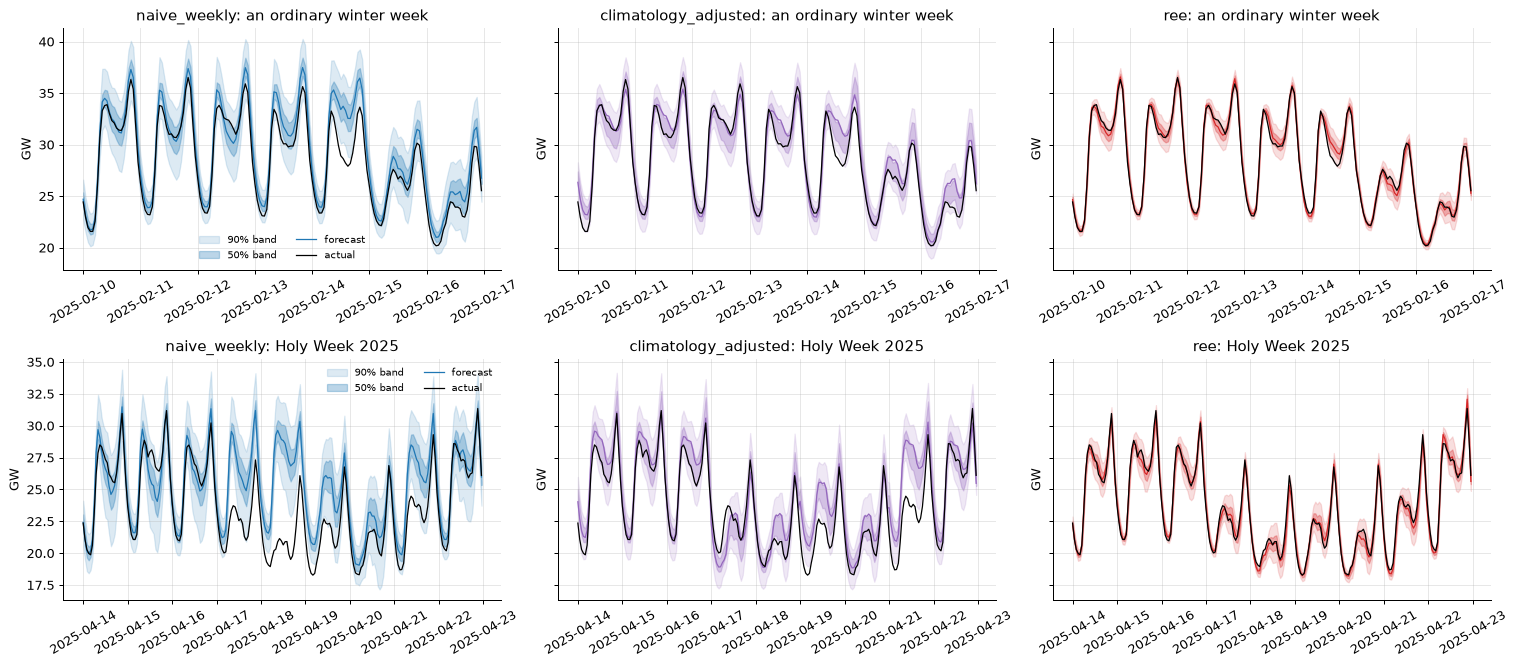

In [7]:
def plot_days(start, end, title, ax_row):
    for ax, m in zip(ax_row, ["naive_weekly", "climatology_adjusted", "ree"], strict=True):
        s = scored[m]
        s = s[(s["local_date"] >= start) & (s["local_date"] <= end)]
        x = s.index.tz_convert("Europe/Madrid").tz_localize(None)
        ax.fill_between(x, s["q0.05"] / 1000, s["q0.95"] / 1000, color=COLORS[m], alpha=0.15, label="90% band")
        ax.fill_between(x, s["q0.25"] / 1000, s["q0.75"] / 1000, color=COLORS[m], alpha=0.3, label="50% band")
        ax.plot(x, s["point"] / 1000, color=COLORS[m], lw=1, label="forecast")
        ax.plot(x, s["y"] / 1000, color="k", lw=1, label="actual")
        ax.set(title=f"{m}: {title}", ylabel="GW")
        ax.tick_params(axis="x", labelrotation=30)
    ax_row[0].legend(frameon=False, fontsize=8, ncol=2)

fig, axes = plt.subplots(2, 3, figsize=(17, 7.5), sharey="row")
plot_days("2025-02-10", "2025-02-16", "an ordinary winter week", axes[0])
plot_days("2025-04-14", "2025-04-22", "Holy Week 2025", axes[1])
fig.tight_layout()
fig.savefig(FIG / "baselines_examples.png", bbox_inches="tight")
plt.show()

## 6. Best and worst days

One score per target day (the mean absolute percentage error over its hours), for three models:
the weekly naive, the adjusted climatology and REE. The question is whether the extreme days have
something in common that a better model could use.

In [8]:
FOCUS = ["naive_weekly", "climatology_adjusted", "ree"]
day_info = table.groupby("local_date").agg(
    weekday=("weekday", "first"), holiday=("holiday_intensity", "first"), bridge=("bridge_intensity", "first"),
    christmas=("christmas", "first"), august=("august", "first"), holy_week=("holy_week", "first"),
    temp=("temp_obs", "mean"), demand_gw=("demand_mw", lambda v: v.mean() / 1000))
day_info["temp_vs_yesterday"] = day_info["temp"].diff()
day_info["temp_vs_last_week"] = day_info["temp"].diff(7)
# a holiday in the week before matters for rules that copy that week
day_info["holiday_week_before"] = day_info["holiday"].shift(7)
day_info["special"] = ((day_info["holiday"] >= 0.3) | (day_info["bridge"] >= 0.5) | day_info["christmas"]
                       | day_info["holy_week"])
day_info["weekday"] = pd.Index(day_info.index).day_name().str[:3]

daily = {}
for m in FOCUS:
    s = scored[m]
    err = s["point"] - s["y"]
    daily[m] = pd.DataFrame({"mape": (100 * err.abs() / s["y"]).groupby(s["local_date"]).mean(),
                             "bias_mw": err.groupby(s["local_date"]).mean()}).join(day_info)
SHOW = ["mape", "bias_mw", "weekday", "holiday", "bridge", "temp", "temp_vs_yesterday", "temp_vs_last_week"]
for m in FOCUS:
    d = daily[m]
    print(f"\n=== {m}: median day {d['mape'].median():.2f}%, mean {d['mape'].mean():.2f}% ===")
    print("Ten worst days:")
    print(d.nlargest(10, "mape")[SHOW].round(2).to_string())
    print("Five best days:")
    print(d.nsmallest(5, "mape")[SHOW].round(2).to_string())


=== naive_weekly: median day 3.69%, mean 5.30% ===
Ten worst days:
            mape   bias_mw weekday  holiday  bridge  temp  temp_vs_yesterday  temp_vs_last_week
local_date                                                                                     
2024-12-25 43.41  9,212.40     Wed     1.00    0.00 10.39               1.14               1.01
2025-04-18 26.45  5,515.09     Fri     1.00    0.00 14.85               1.20              -0.03
2025-01-08 25.03 -7,974.29     Wed     0.00    0.00 11.69               2.59               5.03
2024-12-24 24.32  6,178.66     Tue     0.00    0.00  9.25              -0.58               1.73
2025-05-01 23.06  4,694.11     Thu     1.00    0.00 17.38               0.80               0.48
2025-01-13 20.84 -6,628.29     Mon     0.00    0.00  6.60              -4.04              -4.67
2024-12-26 20.55  4,970.93     Thu     0.18    0.00 10.03              -0.36              -2.50
2025-05-08 20.45 -5,488.28     Thu     0.00    0.00 14.76           

### How the daily scores are distributed

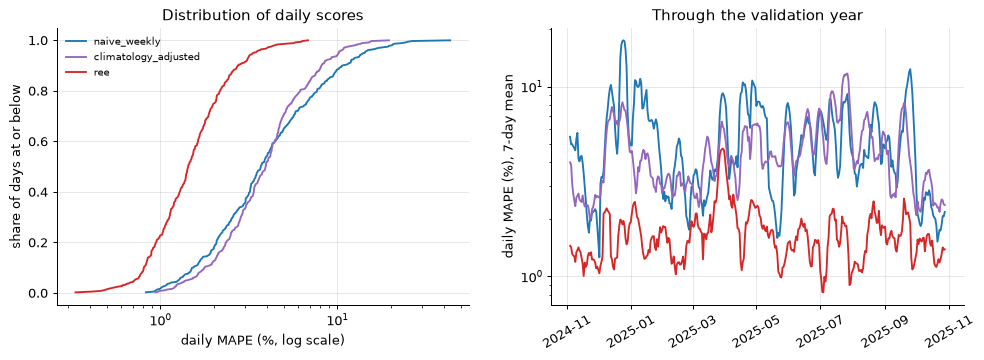

                      best day  10th pct  median  90th pct  worst day  share of total error from the worst 10% of days (%)
naive_weekly              0.83      1.54    3.69     10.68      43.41                                                30.98
climatology_adjusted      0.94      1.78    3.93      8.14      19.57                                                23.81
ree                       0.33      0.81    1.43      2.75       6.82                                                22.91


In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for m in FOCUS:
    v = np.sort(daily[m]["mape"].to_numpy())
    axes[0].plot(v, np.arange(1, len(v) + 1) / len(v), color=COLORS[m], label=m)
axes[0].set(xscale="log", xlabel="daily MAPE (%, log scale)", ylabel="share of days at or below",
            title="Distribution of daily scores")
axes[0].legend(frameon=False, fontsize=8)
for m in FOCUS:
    d = daily[m]["mape"]
    axes[1].plot(d.index, d.rolling(7, center=True).mean(), color=COLORS[m], label=m)
axes[1].set(yscale="log", ylabel="daily MAPE (%), 7-day mean", title="Through the validation year")
axes[1].tick_params(axis="x", labelrotation=30)
fig.savefig(FIG / "baselines_daily_distribution.png", bbox_inches="tight")
plt.show()
rows = {}
for m in FOCUS:
    d = daily[m]["mape"]
    worst = d.nlargest(len(d) // 10)
    rows[m] = {"best day": d.min(), "10th pct": d.quantile(0.1), "median": d.median(), "90th pct": d.quantile(0.9),
               "worst day": d.max(), "share of total error from the worst 10% of days (%)": 100 * worst.sum() / d.sum()}
print(pd.DataFrame(rows).T.round(2).to_string())

### What the extreme days have in common

The worst and the best 10% of days (36 each) against all days.

In [10]:
def describe(d):
    return pd.Series({
        "days": len(d),
        "special days (%)": 100 * d["special"].mean(),
        "holiday the week before (%)": 100 * (d["holiday_week_before"] >= 0.3).mean(),
        "Mondays (%)": 100 * (d["weekday"] == "Mon").mean(),
        "weekend (%)": 100 * d["weekday"].isin(["Sat", "Sun"]).mean(),
        "mean temp (°C)": d["temp"].mean(),
        "|temp change vs yesterday| (°C)": d["temp_vs_yesterday"].abs().mean(),
        "|temp change vs last week| (°C)": d["temp_vs_last_week"].abs().mean(),
        "over-forecast days (%)": 100 * (d["bias_mw"] > 0).mean(),
    })

for m in FOCUS:
    d = daily[m]
    k = len(d) // 10
    print(f"\n{m}")
    print(pd.DataFrame({"worst 10%": describe(d.nlargest(k, "mape")), "all days": describe(d),
                        "best 10%": describe(d.nsmallest(k, "mape"))}).round(1).to_string())


naive_weekly
                                 worst 10%  all days  best 10%
days                                 36.00    363.00     36.00
special days (%)                     33.30      8.30      2.80
holiday the week before (%)          16.70      3.00      0.00
Mondays (%)                          13.90     14.00     11.10
weekend (%)                          19.40     28.70     27.80
mean temp (°C)                       15.70     17.50     16.00
|temp change vs yesterday| (°C)       1.20      0.80      0.70
|temp change vs last week| (°C)       3.30      2.30      1.20
over-forecast days (%)               69.40     45.20     36.10

climatology_adjusted
                                 worst 10%  all days  best 10%
days                                 36.00    363.00     36.00
special days (%)                     19.40      8.30     13.90
holiday the week before (%)           0.00      3.00      2.80
Mondays (%)                          16.70     14.00      5.60
weekend (%)        

### Do the models fail on the same days?

In [11]:
mape_wide = pd.DataFrame({m: daily[m]["mape"] for m in FOCUS})
print("Rank correlation of daily MAPE between models:")
print(mape_wide.corr(method="spearman").round(2).to_string())
k = len(mape_wide) // 10
worst_sets = {m: set(mape_wide[m].nlargest(k).index) for m in FOCUS}
print(f"\nDays in the worst 10% ({k} days) shared between models (about {k * k / len(mape_wide):.0f} expected by chance):")
for i, a in enumerate(FOCUS):
    for b in FOCUS[i + 1:]:
        print(f"  {a} and {b}: {len(worst_sets[a] & worst_sets[b])}")
common = sorted(set.intersection(*worst_sets.values()))
print(f"\nIn the worst 10% of all three ({len(common)} days):")
print(day_info.loc[common, ["weekday", "holiday", "bridge", "christmas", "holy_week", "temp", "temp_vs_last_week"]]
      .join(mape_wide).round(2).to_string())

Rank correlation of daily MAPE between models:
                      naive_weekly  climatology_adjusted  ree
naive_weekly                  1.00                  0.40 0.24
climatology_adjusted          0.40                  1.00 0.18
ree                           0.24                  0.18 1.00

Days in the worst 10% (36 days) shared between models (about 4 expected by chance):
  naive_weekly and climatology_adjusted: 12
  naive_weekly and ree: 9
  climatology_adjusted and ree: 8

In the worst 10% of all three (6 days):
           weekday  holiday  bridge  christmas  holy_week  temp  temp_vs_last_week  naive_weekly  climatology_adjusted  ree
local_date                                                                                                                 
2025-03-30     Sun     0.00    0.00      False      False 12.28               2.62         15.89                  9.26 6.28
2025-03-31     Mon     0.00    0.00      False      False 14.10               4.01         12.37       

### The single worst and best day of each model

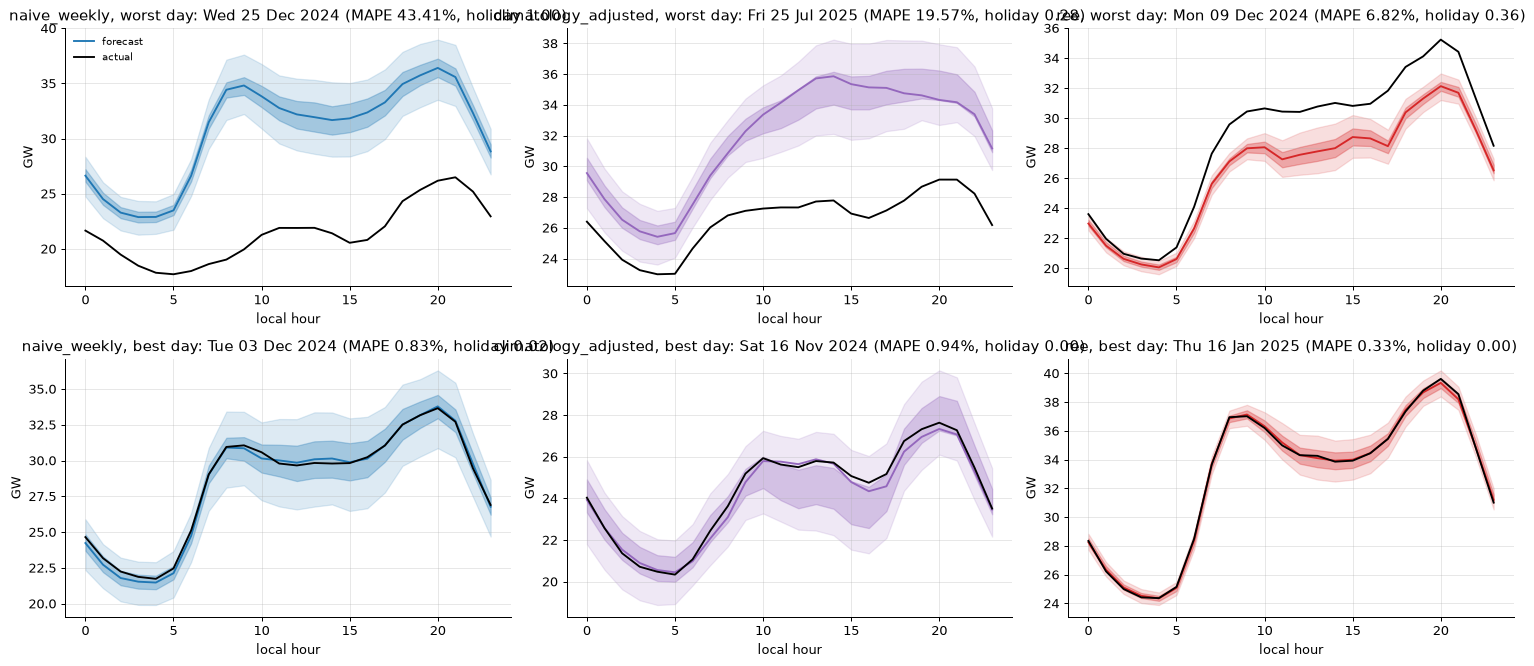

In [12]:
fig, axes = plt.subplots(2, 3, figsize=(17, 7.5))
for col, m in enumerate(FOCUS):
    for row, (kind, date) in enumerate([("worst", daily[m]["mape"].idxmax()), ("best", daily[m]["mape"].idxmin())]):
        ax = axes[row, col]
        s = scored[m]
        s = s[s["local_date"] == date]
        ax.fill_between(s["local_hour"], s["q0.05"] / 1000, s["q0.95"] / 1000, color=COLORS[m], alpha=0.15)
        ax.fill_between(s["local_hour"], s["q0.25"] / 1000, s["q0.75"] / 1000, color=COLORS[m], alpha=0.3)
        ax.plot(s["local_hour"], s["point"] / 1000, color=COLORS[m], label="forecast")
        ax.plot(s["local_hour"], s["y"] / 1000, color="k", label="actual")
        info = day_info.loc[date]
        ax.set(title=f"{m}, {kind} day: {date:%a %d %b %Y} (MAPE {daily[m].loc[date, 'mape']:.2f}%, "
                     f"holiday {info['holiday']:.2f})", xlabel="local hour", ylabel="GW")
axes[0, 0].legend(frameon=False, fontsize=8)
fig.tight_layout()
fig.savefig(FIG / "baselines_best_worst_days.png", bbox_inches="tight")
plt.show()

### A closer look at REE's worst days

Seven of REE's ten worst days fall between 25 March and 1 April 2025, none of them a holiday.
Splitting each day's error into night (00:00–05:59) and midday (11:00–16:59) shows where it comes from.

            night_error_mw  midday_error_mw  midday_radiation  radiation_anomaly  mape
local_date                                                                            
2024-12-09         -510.00        -2,735.00            328.00               4.00  6.82
2025-03-15           58.00         2,523.00            560.00             136.00  4.31
2025-03-25          402.00         2,188.00            573.00              83.00  4.45
2025-03-28          233.00         2,958.00            688.00             161.00  5.66
2025-03-29          -18.00         2,784.00            714.00             171.00  5.78
2025-03-30          138.00         2,839.00            716.00             156.00  6.28
2025-03-31          372.00         2,023.00            717.00             145.00  4.23
2025-04-01          298.00         2,589.00            681.00             102.00  5.05
2025-04-12         -129.00        -2,727.00            439.00            -220.00  4.57
2025-09-22        1,181.00         2,282.00

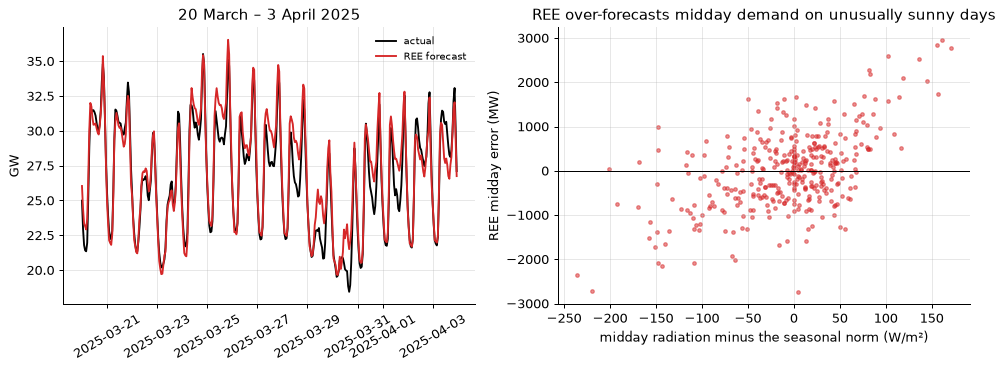

In [13]:
s = scored["ree"].join(table[["rad_obs"]])
s["err"] = s["point"] - s["y"]
parts = pd.DataFrame({
    "night_error_mw": s[s["local_hour"].between(0, 5)].groupby("local_date")["err"].mean(),
    "midday_error_mw": s[s["local_hour"].between(11, 16)].groupby("local_date")["err"].mean(),
    "midday_radiation": s[s["local_hour"].between(11, 16)].groupby("local_date")["rad_obs"].mean(),
})
# radiation relative to what is normal for the time of year (centred 31-day median)
parts["radiation_anomaly"] = parts["midday_radiation"] - parts["midday_radiation"].rolling(31, center=True, min_periods=10).median()
worst10 = daily["ree"].nlargest(10, "mape").index
print(parts.loc[sorted(worst10)].round(0).join(daily["ree"]["mape"].round(2)).to_string())
print("\nAll validation days: correlation of REE's error with the radiation anomaly")
print(f"  midday error: {parts['midday_error_mw'].corr(parts['radiation_anomaly']):.2f}"
      f"   night error: {parts['night_error_mw'].corr(parts['radiation_anomaly']):.2f}")
sunny = parts["radiation_anomaly"] > parts["radiation_anomaly"].quantile(0.9)
dull = parts["radiation_anomaly"] < parts["radiation_anomaly"].quantile(0.1)
print(f"  mean midday error on the 10% sunniest-for-the-season days: {parts.loc[sunny, 'midday_error_mw'].mean():,.0f} MW; "
      f"on the 10% dullest: {parts.loc[dull, 'midday_error_mw'].mean():,.0f} MW")

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
win = s[(s["local_date"] >= "2025-03-20") & (s["local_date"] <= "2025-04-03")]
x = win.index.tz_convert("Europe/Madrid").tz_localize(None)
axes[0].plot(x, win["y"] / 1000, color="k", label="actual")
axes[0].plot(x, win["point"] / 1000, color=COLORS["ree"], label="REE forecast")
axes[0].set(title="20 March – 3 April 2025", ylabel="GW")
axes[0].tick_params(axis="x", labelrotation=30)
axes[0].legend(frameon=False, fontsize=8)
axes[1].scatter(parts["radiation_anomaly"], parts["midday_error_mw"], s=8, alpha=0.5, color=COLORS["ree"])
axes[1].axhline(0, color="k", lw=0.8)
axes[1].set(xlabel="midday radiation minus the seasonal norm (W/m²)", ylabel="REE midday error (MW)",
            title="REE over-forecasts midday demand on unusually sunny days")
fig.savefig(FIG / "baselines_ree_worst_days.png", bbox_inches="tight")
plt.show()

## 7. How errors move within a day

The correlation of forecast errors between hours of the same target day. High values mean the
whole day tends to be wrong in the same direction, which matters for joint scenarios (DESIGN §7.5).

climatology_adjusted: mean correlation between different hours 0.80; sd of the daily mean error 1,365 MW
ree: mean correlation between different hours 0.50; sd of the daily mean error 454 MW


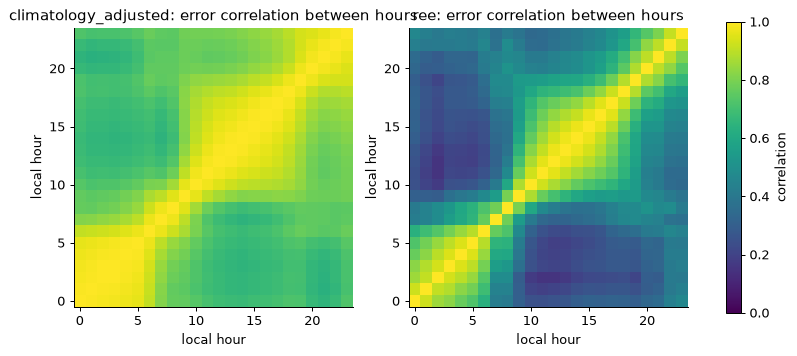

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
for ax, m in zip(axes, ["climatology_adjusted", "ree"], strict=True):
    s = scored[m]
    err = (s["point"] - s["y"]).to_frame("e").assign(d=s["local_date"], h=s["local_hour"])
    corr = err.pivot_table(index="d", columns="h", values="e").corr()
    im = ax.imshow(corr, vmin=0, vmax=1, cmap="viridis", origin="lower")
    ax.set(title=f"{m}: error correlation between hours", xlabel="local hour", ylabel="local hour")
    ax.grid(False)
    off = corr.to_numpy()[~np.eye(24, dtype=bool)].mean()
    print(f"{m}: mean correlation between different hours {off:.2f}; "
          f"sd of the daily mean error {err.groupby('d')['e'].mean().std():,.0f} MW")
fig.colorbar(im, ax=axes, label="correlation")
fig.savefig(FIG / "baselines_error_correlation.png", bbox_inches="tight")
plt.show()

## 8. Conclusions

**The bar set by the baselines**

- The best simple rule is the climatology: MAPE 4.47%, MAE 1,221 MW, CRPS 696 MW. Rescaling it to
  the recent level removes its bias (−153 to −14 MW) but does not improve the scores.
- "Same hour last week" scores 5.29%. It fails on holidays (15.5%), where it copies an ordinary day
  onto a holiday and, a week later, the holiday onto an ordinary day.
- "Latest observed same hour" is the worst at 9.08%. The day it copies is often a different kind of
  day: 12.1% on Mondays, which are forecast from Saturday and Sunday.

**The bar set by REE**

- REE's forecast scores MAPE 1.67%, MAE 455 MW, and CRPS 271 MW with our added quantiles. That is
  about 2.7 times better than the best baseline, and every baseline is significantly worse
  (Diebold–Mariano p below 1e-20).
- REE is weakest on holidays (2.39%) and best in cold weather (1.41%).

**Uncertainty**

- Quantiles built from each forecast's own past errors by hour are close to calibrated in the
  middle but too narrow in the tails: the nominal 90% interval covers 84–89% (REE 88.0%).
- Coverage is not stable through the year, ranging from 75% to 99% by quarter for the adjusted
  climatology. Errors depend on more than the hour (season, kind of day), which this method ignores.
- The plain climatology shows what bias does to calibration: only 41% of outcomes fall below its median.

**Best and worst days (section 6)**

- A few bad days carry much of the error: the worst 10% of days account for 31% of the weekly
  naive's total error, 24% of the climatology's and 23% of REE's.
- Weekly naive: a third of its worst days are holidays, bridge days, Christmas or Holy Week
  (against 8% of all days), and another sixth are the days one week *after* a holiday. Its worst
  day is Christmas Day (43%).
- Adjusted climatology: its worst days are mostly July days cooler than is usual for July (it
  knows the season but not the temperature) and days next to holidays.
- REE: its worst days are **not** holidays (8%, the same share as in the whole year). Seven of
  the ten worst fall between 25 March and 1 April 2025, a run of unusually sunny days, where REE
  over-forecast midday demand by 2–3 GW while its night-time error stayed near zero. Over the whole
  year REE's midday error correlates 0.54 with how sunny the day is for the season (night error:
  −0.09), averaging +1.2 GW on the sunniest tenth of days and −0.8 GW on the dullest. This is
  rooftop solar: on sunny days more demand is met behind the meter than REE expects.
- The three models share some bad days (8 to 12 of 36, where 4 would be chance), but the rank
  correlation of their daily scores is low (0.18–0.40). Each fails for its own reasons.
- The best days are ordinary mid-week working days in stable weather. They show nothing to exploit.

**What this suggests for M3.** Solar radiation (observed for training, forecast at prediction
time) is likely the feature with the most room to gain on REE at midday. Holiday flags for the
lagged days as well as the target day, and the temperature change relative to the lagged days,
address the baselines' failures.

**Dependence within a day.** Errors at different hours of the same day are strongly correlated:
0.80 on average for the climatology and 0.50 for REE. A day is mostly wrong as a whole.

**Targets for the next models (M3 onwards), on this validation year**

| | MAE (MW) | MAPE (%) | CRPS (MW) | 90% coverage (%) |
|---|---:|---:|---:|---:|
| Must beat clearly: best baseline | 1,221 | 4.47 | 696 | 85 |
| Aim to approach: REE | 455 | 1.67 | 271 | 88 |